#**Student Performance Analysis Using DBSCAN**

**Advanced Topic:** DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

## Project Objective

This notebook loads and analyzes a student performance dataset containing student details, attendance, assignment marks, internal marks, and exam marks.

The project demonstrates:

- Viewing and managing student records using CRUD operations.
- Data cleaning, preprocessing, and Exploratory Data Analysis (EDA).
- Statistical analysis of attendance and student marks.
- Data visualization using graphs, scatter plots, and correlation heatmaps.
- Feature scaling and DBSCAN clustering to identify groups of students with similar attendance and academic performance.
- PCA-based cluster visualization, cluster summaries, and identification of unusual data patterns.
- Exporting the final dataset with cluster labels to a CSV file.

**Dataset Features:** `Student_ID`, `Name`, `Attendance`, `Assignment_Marks`, `Internal_Marks`, and `Exam_Marks`.

**Important:** Student ID and name are used for identification, not clustering. DBSCAN uses the four numerical features—attendance, assignment marks, internal marks, and exam marks—to discover patterns in student performance. A noise label indicates an unusual data pattern, not a judgment about a student.

## 1. Import libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score


## 2. Upload your dataset (CSV)

In [8]:
df = pd.read_csv("/content/student_data.csv")

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Dataset loaded successfully!
  Student_ID    Name  Attendance  Assignment_Marks  Internal_Marks  Exam_Marks
0       S001   Aarav          67                51              67          60
1       S002  Unnati          74                58              56          88
2       S003  Vivaan          94                55              87          72
3       S004   Anaya          62                51              55          58
4       S005   Arjun          74                82              88          46
Dataset shape: (200, 6)


## 3. Data preprocessing

In [9]:
# Display dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Clean column names and student names
df.columns = df.columns.str.strip()
df["Name"] = df["Name"].astype("string").str.strip()

# Convert marks and attendance to numeric values
features = [
    "Attendance",
    "Assignment_Marks",
    "Internal_Marks",
    "Exam_Marks"
]

df[features] = df[features].apply(
    pd.to_numeric, errors="coerce"
)

# Remove rows with missing required values
df = df.dropna(subset=["Student_ID", "Name"] + features)

# Keep values within valid ranges
valid = (
    df["Attendance"].between(0, 100)
    & df[features[1:]].apply(
        lambda col: col.between(0, 100)
    ).all(axis=1)
)

df = df[valid].copy()

print("\nCleaned Dataset:")
print(df.head())
print("Final dataset shape:", df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Student_ID        200 non-null    object
 1   Name              200 non-null    object
 2   Attendance        200 non-null    int64 
 3   Assignment_Marks  200 non-null    int64 
 4   Internal_Marks    200 non-null    int64 
 5   Exam_Marks        200 non-null    int64 
dtypes: int64(4), object(2)
memory usage: 9.5+ KB

Missing Values:
Student_ID          0
Name                0
Attendance          0
Assignment_Marks    0
Internal_Marks      0
Exam_Marks          0
dtype: int64

Duplicate Rows: 0

Cleaned Dataset:
  Student_ID    Name  Attendance  Assignment_Marks  Internal_Marks  Exam_Marks
0       S001   Aarav          67                51              67          60
1       S002  Unnati          74                58              56          88
2       S003  Vivaan 

## 4. Clean column names and check duplicate rows
This keeps a copy of the loaded dataset and removes fully duplicated rows. It does not delete columns.

In [10]:
df.columns = [str(c).strip() for c in df.columns]
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows found:", duplicate_count)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicate rows:", df.shape)

# Optional: standardize column names to make code easier to write.
# Original names are retained in a mapping for reference.
column_name_map = {c: c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns}
df = df.rename(columns=column_name_map)
print("Cleaned column names:")
print(df.columns.tolist())

Duplicate rows found: 0
Shape after removing duplicate rows: (200, 6)
Cleaned column names:
['student_id', 'name', 'attendance', 'assignment_marks', 'internal_marks', 'exam_marks']


## 5. Student Management CRUD operations
These functions operate on the in-memory DataFrame. Replace the example column names in the function calls with columns that exist in your dataset.

In [11]:
def read_records(data, n=10):
    display(data.head(n))

def create_record(data, record):
    # record must be a dictionary whose keys match the DataFrame column names
    new_row = pd.DataFrame([record]).reindex(columns=data.columns)
    return pd.concat([data, new_row], ignore_index=True)

def update_record(data, row_index, updates):
    # row_index is the current DataFrame index, not necessarily a student ID
    if row_index not in data.index:
        print("Record index not found.")
        return data
    for column, value in updates.items():
        if column not in data.columns:
            print(f"Column not found: {column}")
            return data
        data.loc[row_index, column] = value
    return data

def delete_record(data, row_index):
    if row_index not in data.index:
        print("Record index not found.")
        return data
    return data.drop(index=row_index).reset_index(drop=True)

# READ: show first 10 records
read_records(df)

# CREATE / UPDATE / DELETE examples are commented out to avoid changing your real dataset accidentally.
# To add a row, edit the keys and values to match your columns:
# df = create_record(df, {"student_id": 999, "attendance": 90})
#
# To update row index 0, use an existing column:
# df = update_record(df, 0, {"attendance": 92})
#
# To delete row index 0:
# df = delete_record(df, 0)

,student_id,name,attendance,assignment_marks,internal_marks,exam_marks
0,S001,Aarav,67,51,67,60
1,S002,Unnati,74,58,56,88
2,S003,Vivaan,94,55,87,72
3,S004,Anaya,62,51,55,58
4,S005,Arjun,74,82,88,46
5,S006,Diya,95,62,95,86
6,S007,Kabir,94,76,64,73
7,S008,Meera,97,67,50,93
8,S009,Ishaan,70,94,77,66
9,S010,Sara,77,59,63,93


## 6. Exploratory Data Analysis (EDA)
Review available numeric columns and plot their distributions. If your dataset has no numeric columns, skip numeric plots.

Numeric columns: ['attendance', 'assignment_marks', 'internal_marks', 'exam_marks']
Categorical columns: ['student_id', 'name']


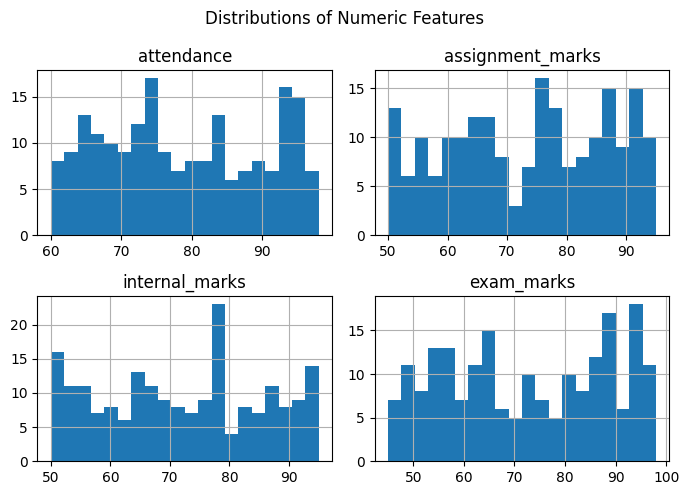

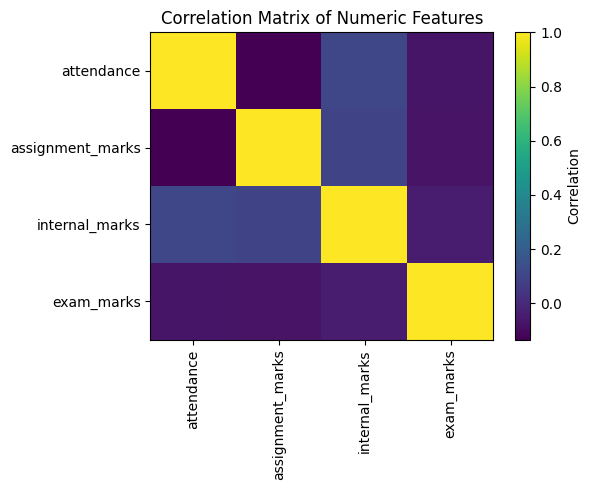

In [20]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

if numeric_cols:
    df[numeric_cols].hist(figsize=(7, 5), bins=20)
    plt.suptitle("Distributions of Numeric Features")
    plt.tight_layout()
    plt.show()

if len(numeric_cols) >= 2:
    plt.figure(figsize=(6, 5))
    corr = df[numeric_cols].corr(numeric_only=True)
    plt.imshow(corr, aspect="auto")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.index)), corr.index)
    plt.colorbar(label="Correlation")
    plt.title("Correlation Matrix of Numeric Features")
    plt.tight_layout()
    plt.show()

## 7. Choose columns for DBSCAN (important)
The code below suggests columns based on common names. **Check the printed list** and edit `FEATURE_COLUMNS` to use the exact columns in your dataset.

Suggested feature categories:
- Study habits / study hours
- Motivation level
- Family background/history (only if appropriate and relevant)
- Attendance
- Learning materials availability
- Physical activity
- Sleep duration
- Extracurricular activities

Do not include a student name/ID, free-text notes, or a target/result column (such as exam score or final grade) unless you have a clear reason. You may exclude family-background fields if they are sensitive or not needed.

In [21]:
# Select DBSCAN features according to your student dataset

# Normalize column names to lowercase_with_underscores
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Display all available columns
print("All available columns:", df.columns.tolist())

# Define features based on your dataset
FEATURE_COLUMNS = [
    "attendance",
    "assignment_marks",
    "internal_marks",
    "exam_marks"
]

# Verify that all selected features exist
missing_columns = [
    col for col in FEATURE_COLUMNS
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("Selected DBSCAN features:", FEATURE_COLUMNS)

    # Prepare numerical data for DBSCAN
    X = df[FEATURE_COLUMNS].apply(
        pd.to_numeric, errors="coerce"
    )

    # Handle missing values
    X = X.fillna(X.median())

    print("\nFeature data preview:")
    display(X.head())

    print("\nFeature data shape:", X.shape)

All available columns: ['student_id', 'name', 'attendance', 'assignment_marks', 'internal_marks', 'exam_marks']
Selected DBSCAN features: ['attendance', 'assignment_marks', 'internal_marks', 'exam_marks']

Feature data preview:


,attendance,assignment_marks,internal_marks,exam_marks
0,67,51,67,60
1,74,58,56,88
2,94,55,87,72
3,62,51,55,58
4,74,82,88,46



Feature data shape: (200, 4)


## 8. Preprocess selected features
Numeric values are imputed with the median and standardized. Categorical values are imputed with the most frequent value and one-hot encoded. This lets DBSCAN process mixed numeric/categorical features.

In [22]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Select numerical features from your student dataset
FEATURE_COLUMNS = [
    "attendance",
    "assignment_marks",
    "internal_marks",
    "exam_marks"
]

# Validate selected features
if not FEATURE_COLUMNS:
    raise ValueError("Please select at least one feature.")

missing_features = [
    c for c in FEATURE_COLUMNS if c not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing columns: {missing_features}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Select features
X_raw = df[FEATURE_COLUMNS].copy()

# Identify numerical and categorical columns
numeric_features = X_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

transformers = []

# Numerical preprocessing: fill missing values and scale
if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

# Categorical preprocessing, if any categorical features are selected
if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

# Apply preprocessing
preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

X_processed = preprocessor.fit_transform(X_raw)

# Display results
print("Selected features:", FEATURE_COLUMNS)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Processed data shape:", X_processed.shape)

print("\nFirst 5 processed records:")
print(X_processed[:5])

Selected features: ['attendance', 'assignment_marks', 'internal_marks', 'exam_marks']
Numeric features: ['attendance', 'assignment_marks', 'internal_marks', 'exam_marks']
Categorical features: []
Processed data shape: (200, 4)

First 5 processed records:
[[-1.05971588 -1.68602191 -0.3762412  -0.78015499]
 [-0.4366154  -1.16043058 -1.18457191  0.96251272]
 [ 1.34367167 -1.385684    1.093451   -0.0332974 ]
 [-1.50478765 -1.68602191 -1.25805652 -0.90463126]
 [-0.4366154   0.64159685  1.16693561 -1.65148885]]


## 9. Apply DBSCAN clustering
`eps` and `min_samples` control how dense a region must be to form a cluster. The default values are starting points, not guaranteed optimal values. Experiment with them and compare the resulting cluster counts.

In [23]:
EPS = 1.2
MIN_SAMPLES = 5

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
labels = dbscan.fit_predict(X_processed)

results = df.copy()
results["DBSCAN_Cluster"] = labels

print("DBSCAN completed.")
print("Number of clusters (excluding noise):", len(set(labels) - {-1}))
print("Number of noise records:", int(np.sum(labels == -1)))
display(results.head(10))

print("Cluster sizes:")
display(results["DBSCAN_Cluster"].value_counts().sort_index().to_frame("record_count"))

DBSCAN completed.
Number of clusters (excluding noise): 1
Number of noise records: 2


,student_id,name,attendance,assignment_marks,internal_marks,exam_marks,DBSCAN_Cluster
0,S001,Aarav,67,51,67,60,0
1,S002,Unnati,74,58,56,88,0
2,S003,Vivaan,94,55,87,72,0
3,S004,Anaya,62,51,55,58,0
4,S005,Arjun,74,82,88,46,0
5,S006,Diya,95,62,95,86,0
6,S007,Kabir,94,76,64,73,0
7,S008,Meera,97,67,50,93,0
8,S009,Ishaan,70,94,77,66,0
9,S010,Sara,77,59,63,93,0


Cluster sizes:


,record_count
DBSCAN_Cluster,
-1,2
0,198


## 10. Visualize clusters using PCA
When there are multiple selected features, PCA projects the processed features to two dimensions for visualization. The plot is an approximation of the feature space; DBSCAN itself was fitted to the processed features.

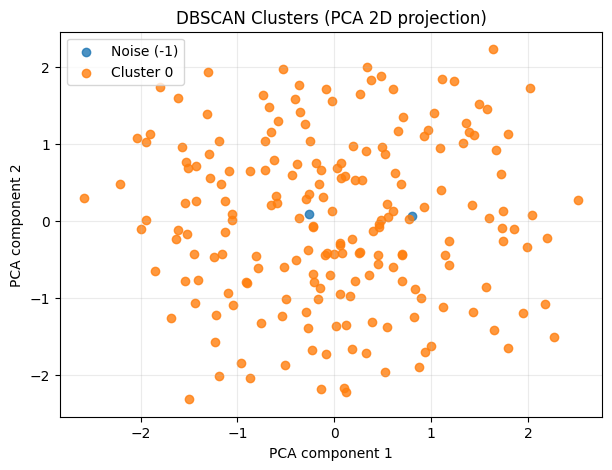

In [25]:
if X_processed.shape[0] >= 2 and X_processed.shape[1] >= 2:
    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(X_processed)
    results["PCA_1"] = coords[:, 0]
    results["PCA_2"] = coords[:, 1]

    plt.figure(figsize=(7, 5))
    for cluster_id in sorted(results["DBSCAN_Cluster"].unique()):
        subset = results[results["DBSCAN_Cluster"] == cluster_id]
        label = "Noise (-1)" if cluster_id == -1 else f"Cluster {cluster_id}"
        plt.scatter(subset["PCA_1"], subset["PCA_2"], label=label, alpha=0.8)
    plt.xlabel("PCA component 1")
    plt.ylabel("PCA component 2")
    plt.title("DBSCAN Clusters (PCA 2D projection)")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()
else:
    print("PCA 2D plot needs at least two processed features and two records.")

## 11. Summarize cluster patterns

In [26]:
# Summarize numeric columns by cluster where possible.
summary_cols = [c for c in numeric_cols if c in results.columns]
if summary_cols:
    cluster_summary = results.groupby("DBSCAN_Cluster")[summary_cols].mean().round(2)
    display(cluster_summary)
else:
    print("No numeric columns available for numeric cluster summaries.")

# Inspect noise records. Noise does not necessarily mean an error or a problematic student.
noise_records = results[results["DBSCAN_Cluster"] == -1]
print("Number of records labeled as noise:", len(noise_records))
display(noise_records.head(20))

,attendance,assignment_marks,internal_marks,exam_marks
DBSCAN_Cluster,,,,
-1,79.0,74.00,69.50,61.00
0,78.9,73.45,72.15,72.65


Number of records labeled as noise: 2


,student_id,name,attendance,assignment_marks,internal_marks,exam_marks,DBSCAN_Cluster,PCA_1,PCA_2
129,S130,Sara,62,56,88,72,-1,-0.258662,0.084499
181,S182,Anvi,96,92,51,50,-1,0.803850,0.064313


## 12. Export clustered dataset
The output CSV includes the original data plus the DBSCAN cluster label (and PCA coordinates if generated).

In [27]:
OUTPUT_FILE = "student_dataset_dbscan_results.csv"
results.to_csv(OUTPUT_FILE, index=False)
print("Saved:", OUTPUT_FILE)

# To download the CSV from Google Colab, uncomment:
# from google.colab import files
# files.download(OUTPUT_FILE)

Saved: student_dataset_dbscan_results.csv


## 13. Conclusion
This notebook combines student-record CRUD examples with data analysis and DBSCAN clustering. It preprocesses selected study and lifestyle characteristics, groups records by density, visualizes the result with PCA, and exports cluster labels.

### Future scope
- Compare DBSCAN with K-Means or hierarchical clustering.
- Tune `eps` and `min_samples` and document how cluster counts change.
- Build a dashboard or connect the workflow to a database.
- Use privacy-aware handling of student and family information.

**For your report:** State the exact feature columns and DBSCAN parameters you used, and discuss the observed clusters without treating clusters as judgments about individual students.